# Our own two grippers, chosen by the local VLM

    Objaverse object  →  Qwen3-VL-2B  →  2-finger or 4-finger  →  GraspGenX  →  grasp poses

`pipeline_objaverse.ipynb` ran this with `franka_panda` and `robotiq_2f_140`, the two grippers
GraspGenX ships. This one uses **our own fin-ray pair** instead, and only the local
**Qwen3-VL-2B-Instruct-4bit** — no Gemini.

Two things are different from that notebook, on purpose:

1. **The objects are split 50/50 by shape**, so the decision is not one-sided by construction:
   five roughly round objects, where four fingers could cage what two fingers would let roll, and
   five clearly elongated ones with two obvious parallel faces.
2. **The VLM is asked to say why**, one line per object, so we can see whether the choice follows
   from the shape or is just a habit.

One caveat stated up front, because it shapes how to read the result:
`graspgenx_unseen_objects_4f.ipynb` already showed that **GraspGenX cannot plan for our 4-finger
gripper** — its grasps land tens of millimetres short of the object. So if the VLM routes objects
to 4-finger, stage 3 will fail on them. We measure that here rather than hide it.

## 1. Setup

In [1]:
import json, os, pathlib, subprocess, time
import numpy as np, pandas as pd, trimesh, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

os.environ["GRASPGENX_DEVICE"] = "cpu"

from graspgenx import get_checkpoints_version_dir
from graspgenx.grasp_server import GraspGenXSampler
from graspgenx.utils.checkpoint_io import load_model_cfg
from graspgenx.x_grippers import make_sweep_volume_gripper_info

ROOT   = pathlib.Path.cwd()
MESHES = ROOT/"data"/"objaverse"/"meshes"
OUT    = ROOT/"stage1_gripper"/"results"/"demo"
QWEN   = "mlx-community/Qwen3-VL-2B-Instruct-4bit"

objects = json.loads((OUT/"objects.json").read_text())
print(f"{len(objects)} objects, "
      f"{sum(o['shape']=='round' for o in objects.values())} round / "
      f"{sum(o['shape']=='elongated' for o in objects.values())} elongated")

2026-09-18 09:45:44,972 - OpenGL.acceleratesupport - INFO - OpenGL_accelerate module loaded


2026-09-18 09:45:44,992 - OpenGL.arrays.arraydatatype - INFO - Using accelerated ArrayDatatype


2026-09-18 09:45:45,135 - graspgenx.dataset.dataset - WARNING - Could not import renderer (pyrender): dlsym(0x330bff124, class_getMethodImplementation_stret): symbol not found. Rendering functions will be unavailable (OK for training).


10 objects, 5 round / 5 elongated


## 2. Does Objaverse give us images, or only geometry?

Both, it turns out. The assets themselves are textured meshes, but the Objaverse annotations also
carry a real **name**, a tag list, and **five thumbnail images** per object, uploaded with the
model on Sketchfab. `objaverse.load_annotations()` fetches them.

That is better than what we had before: the object labels in `pipeline_objaverse.ipynb` were names
*I* wrote after looking at renders. These come from the dataset.

So each object gets shown to the VLM twice over — the dataset thumbnail, and a two-view render of
the mesh at its true scale — plus its real name.

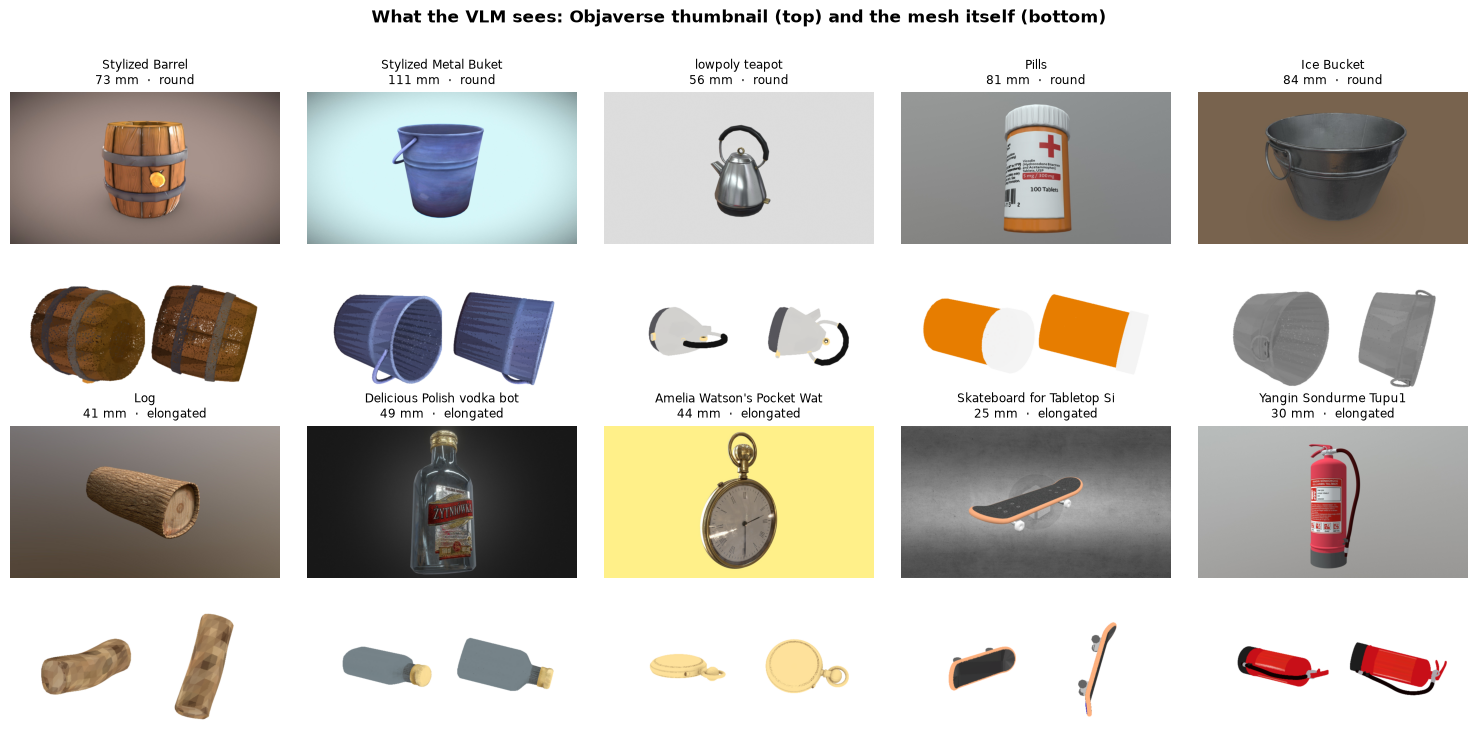

In [2]:
fig, axes = plt.subplots(4, 5, figsize=(15, 7.4),
                         gridspec_kw={"height_ratios": [1.3, 1, 1.3, 1]})
for col, (key, o) in enumerate(objects.items()):
    r, c = (0 if col < 5 else 2), col % 5
    thumb = OUT/"thumbs"/f"{key}.jpg"
    axes[r][c].imshow(plt.imread(thumb)); axes[r][c].axis("off")
    axes[r][c].set_title(f"{o['name'][:26]}\n{o['short_mm']:.0f} mm  ·  {o['shape']}",
                         fontsize=8.5)
    axes[r+1][c].imshow(plt.imread(OUT/"renders"/f"{key}.png")); axes[r+1][c].axis("off")
fig.suptitle("What the VLM sees: Objaverse thumbnail (top) and the mesh itself (bottom)",
             fontsize=12, fontweight="bold", y=.99)
fig.tight_layout(rect=(0, 0, 1, .97))
fig.savefig(OUT/"finray_inputs.png", dpi=140, facecolor="white")
plt.show()

## 3. The two grippers

Same body, same fingers, measured from the printed STLs. The only thing that changes in what
GraspGenX is told is the **y** extent of the swept box — 30 mm for two fingers, 148 mm for four,
because the second pair closes along the other axis.

In [3]:
params = json.load(open(ROOT/"data"/"gripper"/"params_legacy.json"))["grippers"]

infos, geom = {}, {}
for tag in ["2-finger", "4-finger"]:
    g = params[tag]
    infos[tag] = make_sweep_volume_gripper_info(
        g["extents_open"], g["offset_open"], g["extents_mid"], g["offset_mid"],
        name=f"finray_{tag[0]}f")
    geom[tag] = dict(
        reach = g["extents_open"][0]/2,                              # centre to each finger
        z_tip = g["offset_open"][2] + g["extents_open"][2]/2,         # front of the swept box
        z_back= g["offset_open"][2] - g["extents_open"][2]/2,
        dirs  = ([(1,0), (-1,0)] if g["n_contacts"] == 2
                 else [(1,0), (-1,0), (0,1), (0,-1)]))
    print(f"{tag}: swept box {[round(v*1000,1) for v in g['extents_open']]} mm, "
          f"{g['n_contacts']} fingers {geom[tag]['reach']*1000:.1f} mm out")

2-finger: swept box [148.1, 30.0, 38.3] mm, 2 fingers 74.1 mm out
4-finger: swept box [148.1, 148.1, 38.3] mm, 4 fingers 74.1 mm out


## 4. Stage 2 — Qwen picks a gripper, and says why

The model gets the thumbnail, the mesh render, the dataset name and the measured size. It runs in
the `mlxvlm` conda env (MLX and GraspGenX cannot share one — GraspGenX pins numpy 1.26.4), so the
notebook calls `stage1_gripper/scripts/qwen_pick_finray.py` as a subprocess.

**Zero-shot.** The fine-tuned Stage 2 LoRA does cover this exact decision, but it was trained on
33 photographs of our gripper mid-grasp; pointing it at Objaverse renders is the domain shift we
already measured in Stage 3. Zero-shot is the cleaner baseline here.

Each object is asked twice, with the grippers listed in both orders, so a constant answer can be
told from option-order bias.

In [4]:
PICK_FILE = OUT/"qwen_finray_picks.json"
if not PICK_FILE.exists():
    subprocess.run(["/opt/anaconda3/envs/mlxvlm/bin/python",
                    "stage1_gripper/scripts/qwen_pick_finray.py", str(OUT), str(PICK_FILE)], check=True)

picks = json.loads(PICK_FILE.read_text())
for key, o in objects.items():
    o.update(picks[key])
    flag = "" if o["gripper"] == o["swapped_order"] else "   <- flips when reordered"
    print(f"{o['shape']:9s} {o['name'][:26]:26s} -> {str(o['gripper']):9s}{flag}")
    print(f"{'':38s}    \"{o['reason'][:96]}\"")

round     Stylized Barrel            -> 2-finger 
                                          "The barrel is 73 mm across its shortest axis, which is the diameter of the barrel."
round     Stylized Metal Buket       -> 2-finger 
                                          "The bucket is relatively narrow and cylindrical, with a handle that is short and wide, making it"
round     lowpoly teapot             -> 2-finger 
                                          "The teapot is small and has a rounded, conical body that is best gripped with two fingers from o"
round     Pills                      -> 2-finger 
                                          "The object is a small, cylindrical pill bottle with a rounded cap and a label that is slightly w"
round     Ice Bucket                 -> 2-finger 
                                          "The bucket is relatively wide and has a rounded rim, making it suitable for a 2-finger gripper t"
elongated Log                        -> 2-finger 
         

## 5. Stage 3 — GraspGenX, with whatever the VLM chose

`standoff` is how far past the fingertips the object begins. Zero or less means the fingers reach
it; positive means the gripper stopped short and would close on air.

In [5]:
ckpt = get_checkpoints_version_dir()
cfg  = load_model_cfg(str(ckpt/"gen"), str(ckpt/"dis"))
scales = json.loads((ROOT/"data"/"objaverse"/"scales.json").read_text())

model, samplers = None, {}
for tag in ["2-finger", "4-finger"]:
    samplers[tag] = GraspGenXSampler(cfg, gripper_info=infos[tag], model=model)
    model = samplers[tag].model


def load_points(uuid):
    mesh = trimesh.load(MESHES/f"{uuid}.glb", force="mesh")
    mesh.apply_scale(scales[uuid])                      # Objaverse units -> metres
    pts = np.asarray(trimesh.sample.sample_surface(mesh, 3500)[0], np.float32)
    centre = pts.mean(0); pts -= centre
    dense = np.asarray(trimesh.sample.sample_surface(mesh, 40000)[0]) - centre
    return pts, dense


def standoff_mm(pose, dense, tag):
    """How far past the fingertips the object begins. <= 0 means the fingers reach it."""
    Ti = np.linalg.inv(pose)
    p = dense @ Ti[:3, :3].T + Ti[:3, 3]
    return (p[:, 2].min() - geom[tag]["z_tip"]) * 1000


def plan(pts, dense, tag):
    poses, conf = GraspGenXSampler.run_inference(
        pts, samplers[tag], grasp_threshold=-1.0, num_grasps=200,
        topk_num_grasps=20, remove_outliers=False)
    poses, conf = poses.cpu().numpy(), conf.cpu().numpy()
    off = np.array([standoff_mm(T, dense, tag) for T in poses])
    return poses, conf, off


for key, o in objects.items():
    t = time.time()
    o["pts"], o["dense"] = load_points(o["uuid"])
    tag = o["gripper"]
    o["poses"], o["conf"], o["standoff"] = plan(o["pts"], o["dense"], tag)
    o["reaches"] = float(np.mean(o["standoff"] <= 0))
    print(f"{o['name'][:24]:24s} {tag:9s} score {o['conf'].max():.2f}  "
          f"standoff {np.median(o['standoff']):6.1f} mm  "
          f"{o['reaches']:4.0%} of grasps reach  {time.time()-t:.1f}s")

Generator checkpoint : /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/gen/epoch_736.pth
Discriminator checkpoint: /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/dis/epoch_1056.pth
Generator      : backbone=ptv3vanilla, gripper=sweep_volume_v2, obj_dim=512, embed_dim=512, pointnet_ver=v2
  DDPM         : train_steps=20, eval_steps=20, beta_schedule=squaredcos_cap_v2, clip_sample=True, compositional=True
  Grasp        : grasp_repr=r3_so3, kappa(noise_scale)=3.27, pose_repr=mlp
Discriminator  : backbone=ptv3vanilla, gripper=sweep_volume_v2, obj_dim=512, embed_dim=256, pointnet_ver=v2
  Grasp        : grasp_repr=r3_so3, kappa(noise_scale)=3.27, pose_repr=mlp


2026-09-18 09:45:49,930 - graspgenx.models.discriminator - INFO - Pose representation is mlp


2026-09-18 09:45:49,932 - graspgenx.models.grasp_gen - INFO - Loading generator checkpoint from /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/gen/epoch_736.pth


2026-09-18 09:45:50,710 - graspgenx.models.grasp_gen - INFO - Loading discriminator checkpoint from /Users/diptidhawade/Plaksha/Code/CVP/Project/GraspGenX/ext/graspgenx_checkpoints/release/dis/epoch_1056.pth


2026-09-18 09:45:51,969 - graspgenx.grasp_server - INFO - Confidences min: 0.00043, max: 0.90405


...

2026-09-18 09:46:10,484 - graspgenx.grasp_server - INFO - Confidences min: 0.04342, max: 0.98175


2026-09-18 09:46:10,485 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-18 09:46:10,486 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 2, total grasps: 40


2026-09-18 09:46:10,486 - graspgenx.grasp_server - INFO - Time taken for inference: 0.7159268856048584 seconds


Yangin Sondurme Tupu1    2-finger  score 0.98  standoff   -8.7 mm   95% of grasps reach  1.7s


## 6. The result

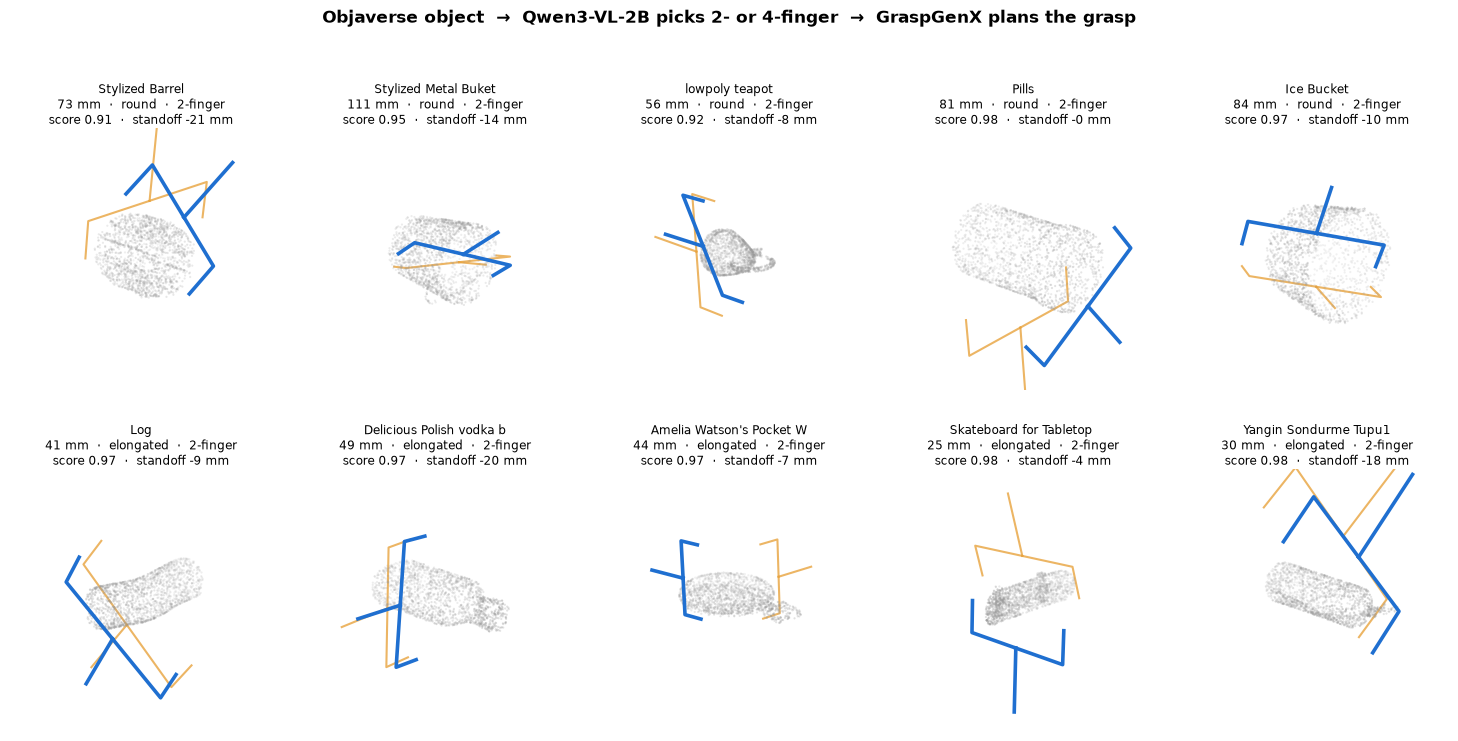

In [6]:
def wireframe(pose, tag):
    """The gripper's fingers, drawn from its swept volume."""
    g = geom[tag]
    segs = [[[0, 0, g["z_back"]], [0, 0, 0]]]                        # stem to the base
    for dx, dy in g["dirs"]:
        segs.append([[0, 0, g["z_back"]],
                     [g["reach"]*dx, g["reach"]*dy, g["z_back"]],    # spoke to the knuckle
                     [g["reach"]*dx, g["reach"]*dy, g["z_tip"]]])    # the finger
    return [(pose @ np.c_[np.array(s), np.ones(len(s))].T).T[:, :3] for s in segs]


fig = plt.figure(figsize=(15, 7.4))
for i, (key, o) in enumerate(objects.items()):
    tag  = o["gripper"]
    top2 = np.argsort(-o["conf"])[:2]

    ax = fig.add_subplot(2, 5, i+1, projection="3d")
    ax.scatter(*o["pts"][::2].T, s=2.5, c="0.6", alpha=.55, linewidths=0)
    for rank, k in enumerate(reversed(top2)):
        best = rank == len(top2)-1
        for seg in wireframe(o["poses"][k], tag):
            ax.plot(*seg.T, color="#1f6fd0" if best else "#e8a33d",
                    lw=2.6 if best else 1.5, alpha=1.0 if best else .8,
                    zorder=3 if best else 2)

    lim = max(np.abs(o["pts"]).max(),
              max(np.abs(s).max() for s in wireframe(o["poses"][top2[0]], tag)))
    for setter in (ax.set_xlim, ax.set_ylim, ax.set_zlim): setter(-lim, lim)
    ax.set_box_aspect((1, 1, 1), zoom=1.5)
    ax.view_init(elev=20, azim=45); ax.set_axis_off()
    ax.set_title(f"{o['name'][:24]}\n{o['short_mm']:.0f} mm  ·  {o['shape']}  ·  {tag}\n"
                 f"score {o['conf'].max():.2f}  ·  standoff "
                 f"{o['standoff'][top2[0]]:.0f} mm",
                 fontsize=8.5, pad=-2)

fig.suptitle("Objaverse object  →  Qwen3-VL-2B picks 2- or 4-finger  →  GraspGenX plans the grasp",
             fontsize=12.5, fontweight="bold", y=.995)
fig.subplots_adjust(top=.835, bottom=.02, left=.01, right=.99, wspace=0, hspace=.3)
fig.savefig(OUT/"pipeline_finray_qwen.png", dpi=150, facecolor="white")
plt.show()

## 7. Would the other gripper have done better?

Each object planned again with the gripper the VLM did *not* pick.

In [7]:
rows = []
for key, o in objects.items():
    other = "4-finger" if o["gripper"] == "2-finger" else "2-finger"
    _, conf_o, off_o = plan(o["pts"], o["dense"], other)
    rows.append(dict(object=o["name"][:26], shape=o["shape"],
                     short_mm=round(o["short_mm"]), picked=o["gripper"],
                     picked_standoff=round(float(np.median(o["standoff"])), 1),
                     picked_reaches=round(o["reaches"], 2),
                     other=other,
                     other_standoff=round(float(np.median(off_o)), 1),
                     other_reaches=round(float(np.mean(off_o <= 0)), 2)))

table = pd.DataFrame(rows)
table.to_csv(OUT/"pipeline_finray_qwen.csv", index=False)
print(f"grasps that reach the object — as picked {table.picked_reaches.mean():.0%}, "
      f"with the other gripper {table.other_reaches.mean():.0%}")
print(f"median standoff — as picked {table.picked_standoff.median():.1f} mm, "
      f"other {table.other_standoff.median():.1f} mm\n")
table

2026-09-18 09:46:12,157 - graspgenx.grasp_server - INFO - Confidences min: 0.00597, max: 0.73143


2026-09-18 09:46:12,158 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-18 09:46:12,159 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 1, total grasps: 20


2026-09-18 09:46:12,159 - graspgenx.grasp_server - INFO - Time taken for inference: 0.9497311115264893 seconds


2026-09-18 09:46:13,070 - graspgenx.grasp_server - INFO - Confidences min: 0.00475, max: 0.69905


...

2026-09-18 09:46:30,550 - graspgenx.grasp_server - INFO - Thresholding grasps @ -1.0. Only 200/200 grasps remaining


2026-09-18 09:46:30,552 - graspgenx.grasp_server - INFO - Found 20 grasps in iteration 2, total grasps: 40


2026-09-18 09:46:30,552 - graspgenx.grasp_server - INFO - Time taken for inference: 0.7669291496276855 seconds


grasps that reach the object — as picked 84%, with the other gripper 0%
median standoff — as picked -9.9 mm, other 27.8 mm



,object,shape,short_mm,picked,picked_standoff,picked_reaches,other,other_standoff,other_reaches
0,Stylized Barrel,round,73,2-finger,-10.5,0.88,4-finger,30.0,0.0
1,Stylized Metal Buket,round,111,2-finger,0.6,0.45,4-finger,35.4,0.0
2,lowpoly teapot,round,56,2-finger,-8.7,0.90,4-finger,29.0,0.0
3,Pills,round,81,2-finger,-15.8,0.97,4-finger,24.9,0.0
4,Ice Bucket,round,84,2-finger,-3.8,0.65,4-finger,26.5,0.0
5,Log,elongated,41,2-finger,-9.4,0.85,4-finger,27.4,0.0
6,Delicious Polish vodka bot,elongated,49,2-finger,-16.9,0.95,4-finger,28.0,0.0
7,Amelia Watson's Pocket Wat,elongated,44,2-finger,-10.7,0.95,4-finger,24.1,0.0
8,Skateboard for Tabletop Si,elongated,25,2-finger,-13.9,0.90,4-finger,27.6,0.0
9,Yangin Sondurme Tupu1,elongated,30,2-finger,-8.7,0.95,4-finger,31.6,0.0


## 8. What this shows

**Qwen3-VL-2B answered `2-finger` for all ten objects, including the five chosen precisely because
four fingers should help.**

That is not option-order bias — asked again with the grippers listed in the other order, it gave
the same answer ten times out of ten. And it is not a preference for the bigger or the
first-listed option either: in `pipeline_objaverse.ipynb`, faced with franka versus robotiq, the
same model answered `robotiq_2f_140` for all ten objects there. **The constant changes with the
framing; the constancy does not.**

The reasoning it produces is fluent and does not discriminate. For the Ice Bucket — 84 mm, round,
open-topped — it wrote *"The bucket is relatively wide and has a rounded rim, making it suitable
for a 2-finger gripper that can grasp the sides from opposite sides."* For the vodka bottle it
wrote almost the same sentence with different nouns. The reasons restate the measurements we
handed it and then assert the answer it was always going to give. **Asking a 2 B model to explain
itself gets you an explanation, not a decision.**

That was the point of splitting the objects 50/50 by shape. Five round objects — barrel, bucket,
teapot, pill bottle, ice bucket — are exactly where caging with four fingers should beat two
contacts that let the object roll. The model never once chose it. A single-number score would have
hidden that; the split makes it visible.

**Stage 3 worked anyway, for a reason that has nothing to do with the VLM.** With the 2-finger
gripper, 84% of GraspGenX's grasps reach the object, median standoff −10 mm — the fingers close on
it. Planned again with 4-finger, **0% of grasps reach, on every single object**, median standoff
+28 mm. Qwen's constant answer happens to coincide with the only one of our two grippers GraspGenX
can serve at all. The pipeline produces good output by luck.

**One mismatch worth knowing about.** The thumbnails in section 2 are Sketchfab renders of the
original full-detail assets; the meshes GraspGenX plans on are GraspGen's watertight *simplified*
versions. Compare the teapot: a detailed kettle in the thumbnail, a smooth blob in the render. The
VLM is looking at a better object than the planner is.

**Caveats.** This does not show 4-finger is wrong for the round objects — only that GraspGenX
cannot plan for it, which we already knew. And because the VLM never varies, this test cannot
separate a good decision from a lucky one; it can only show that no decision is being made.

**What would move this forward:** fine-tuning on this decision specifically. The Stage 2 LoRA
covers the same two grippers but was trained on 33 photographs of the real gripper mid-grasp, and
Stage 3 already measured what that domain shift costs. Labelled 2-versus-4-finger preferences on
rendered objects is the missing training data.